# CS-781 Capstone, Phase 1: Legal Language Model (from scratch)


| Component | Where it comes from |
|---|---|
| Tokenizer (byte-level BPE: training, encoding, decoding) | Written in this notebook, trained on the firm corpus |
| Transformer (RoPE, GQA, RMSNorm, SwiGLU, KV-cache) | Written in this notebook in plain PyTorch |
| Weights | Random init, trained on the Phase-1 corpus only |
| Pretrained models / external data | None |

Pipeline: **stream and clean -> train BPE -> pack tokens -> train ~121M decoder -> tune decoding locally -> prediction.json -> submission.zip**

## 1. Configuration

In [1]:
import os, sys, json, re, math, time, zlib, hashlib, random, zipfile, heapq, subprocess
from collections import Counter, defaultdict
from dataclasses import dataclass
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

DEBUG = False            # True = tiny end-to-end smoke test (minutes, not hours)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
OUTPUT_DIR = "/kaggle/working/cs781_phase1"
os.makedirs(OUTPUT_DIR, exist_ok=True)
PREDICTION_PATH = f"{OUTPUT_DIR}/prediction.json"
SUBMISSION_ZIP = f"{OUTPUT_DIR}/submission.zip"

# --- Data plan: (file, keep-probability, word budget, min words per document) ---
# Keep-probability samples documents across the WHOLE file (so we do not just take the
# first, possibly oldest, judgments). Budgets of ~110M words are roughly 150M tokens.
SOURCES = {
    "supreme_court": ("train_supreme_court.json", 0.15, 66_000_000, 200),
    "high_courts":   ("train_high_courts.json",   0.05, 27_000_000, 200),
    "tribunals":     ("train_tribunals.json",     0.15,  8_000_000, 200),
    "acts":          ("train_acts.json",          1.00,  9_000_000,  50),
}
MAX_WORDS_PER_DOC = 8_000        # cap pathological outliers, keep the head
VAL_MOD = 100                    # ~1% of documents are held out (split by document hash)

# --- Tokenizer ---
VOCAB_SIZE = 32_000
TOKENIZER_CHARS_PER_SOURCE = 40_000_000
TOKENIZER_MIN_WORD_FREQ = 3

# --- Model (about 121M parameters at these settings) ---
CONTEXT = 1280                   # 512-word prompt is ~700-900 tokens, plus ~250 generated
N_LAYER, N_HEAD, N_KV_HEAD, N_EMBD, N_FFN = 12, 12, 4, 768, 2816
GRAD_CKPT = False                # True trades ~30% speed for much lower memory

# --- Optimisation ---
MICRO_BS, GRAD_ACCUM = 4, 16     # 4*16*1280 = ~82k tokens per optimizer step
LR, MIN_LR, WEIGHT_DECAY, WARMUP_FRAC = 6e-4, 6e-5, 0.1, 0.03
EVAL_EVERY, EVAL_BATCHES, LOG_EVERY = 200, 60, 20
MAX_TRAIN_HOURS = 10.0           # safety stop for Kaggle's session limit; resume afterwards

# --- Generation ---
PROMPT_WORDS, TARGET_WORDS = 512, 128
MAX_NEW_TOKENS = 256
EOS_PLACEHOLDER = "<|endoftext|>"

if DEBUG:
    SOURCES = {k: (v[0], 1.0, 300_000, v[3]) for k, v in SOURCES.items()}
    VOCAB_SIZE, TOKENIZER_CHARS_PER_SOURCE, TOKENIZER_MIN_WORD_FREQ = 4_000, 2_000_000, 2
    CONTEXT, N_LAYER, N_HEAD, N_KV_HEAD, N_EMBD, N_FFN = 256, 2, 4, 2, 128, 352
    EVAL_EVERY, EVAL_BATCHES, LOG_EVERY, MICRO_BS, GRAD_ACCUM = 20, 5, 5, 8, 2
    MAX_NEW_TOKENS = 64
    VAL_MOD = 10

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "")

device: cuda | Tesla T4


## 2. Access the dataset and inspect the test prompts
The cleaning rules depend on what the test prompts look like, so we check them first
(do they contain newlines? how many tokens will they need?).

In [2]:
from huggingface_hub import HfApi, hf_hub_download, login

try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("capstone-phase1-token")
    os.environ["HF_TOKEN"] = HF_TOKEN
    login(token=HF_TOKEN)
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

_repo_files = HfApi().list_repo_files(HF_DATASET_REPO, repo_type="dataset", token=HF_TOKEN)

def fetch(*must_contain):
    """Find a repo file whose path contains all given substrings (case-insensitive)."""
    hits = [f for f in _repo_files if all(s.lower() in f.lower() for s in must_contain)]
    if not hits:
        raise FileNotFoundError(f"{must_contain} not found. Repo has: {_repo_files[:40]}")
    return hf_hub_download(HF_DATASET_REPO, hits[0], repo_type="dataset", token=HF_TOKEN)

test_path = fetch("phase_1", "test", ".json")
with open(test_path, encoding="utf-8") as f:
    test_data = json.load(f)
test_prompts_raw = [v["text"] for v in test_data.values()]
frac_nl = np.mean(["\n" in p for p in test_prompts_raw])
KEEP_NEWLINES = bool(frac_nl > 0.5)
print(f"test prompts: {len(test_prompts_raw)} | with newlines: {frac_nl:.0%} "
      f"| median words: {np.median([len(p.split()) for p in test_prompts_raw]):.0f}")
print("KEEP_NEWLINES =", KEEP_NEWLINES, "(training text is formatted to match the test prompts)")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

test prompts: 1000 | with newlines: 0% | median words: 512
KEEP_NEWLINES = False (training text is formatted to match the test prompts)


In [3]:
test_prompts_raw[1]

'Instead of taking cognizance of the offence, he has, in the exercise of his discretion, sent the complaint for investigation by police under Section 156." 12) In Tula Ram & Ors. vs. Kishore Singh (supra) again this Court considered order for investigation under [Section 2] 156 (3) on a complaint. After considering various earlier decisions, the Court on a careful consideration of the facts and circumstances of the case propounded the following legal propositions:- ".... 1. That a Magistrate can order investigation under [S. 156 (3)] only at the pre-cognizance stage, that is to say, before taking cognizance under Sections 190, 200 and 204 and where a Magistrate decides to take cognizance under the provisions of Chapter 14 he is not entitled in law to order any investigation under Section 156 (3) though in cases not falling within the proviso to Section 202 he can order an investigation by the police which would be in the nature of an enquiry as contemplated by Sec. 202 of the Code. 2. 

## 3. Cleaning rules for Indian legal text
**Keep:** statutory citations ("Section 302 IPC", "(2011) 4 SCC 1"), case names, numbers, and the
full reasoning. These carry the legal semantics.
**Remove:** page furniture (page numbers, portal stamps, digital-signature lines), control characters,
OCR junk, very short documents, near-empty or highly repetitive documents, exact duplicates.
**Normalise:** curly quotes and dashes to ASCII, whitespace to match the test prompts.
The same character/whitespace normalisation is applied to test prompts at inference time.

In [4]:
BOILERPLATE = [
    re.compile(r"^\s*page\s+\d+(\s+of\s+\d+)?\s*$", re.I),
    re.compile(r"^\s*-?\s*\d{1,4}\s*-?\s*$"),                          # bare page numbers
    re.compile(r"^\s*(https?://|www\.)\S+\s*$", re.I),
    re.compile(r"^\s*(indian\s*kanoon|manupatra|scc\s*online|supreme\s*court\s*cases)\b.*$", re.I),
    re.compile(r"^\s*(digitally\s+signed\s+by|signature\s+not\s+verified|reason:|location:)\b.*$", re.I),
    re.compile(r"^\s*(reportable|non-?reportable)\s*$", re.I),
]
CHAR_MAP = str.maketrans({
    "\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u2013": "-", "\u2014": "-",
    "\u2212": "-", "\u2026": "...", "\u00a0": " ", "\u200b": "", "\ufeff": "", "\u00ad": "",
})
CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]")

def normalize_text(t: str, keep_newlines: bool) -> str:
    """Character and whitespace normalisation. Applied to train text AND test prompts."""
    t = CTRL.sub(" ", t.translate(CHAR_MAP))
    if keep_newlines:
        t = re.sub(r"[ \t]+", " ", t)
        t = re.sub(r" ?\n ?", "\n", t)
        t = re.sub(r"\n{3,}", "\n\n", t)
    else:
        t = re.sub(r"\s+", " ", t)
    return t.strip()

def clean_document(t: str, keep_newlines: bool) -> str:
    kept = [l for l in t.splitlines() if not any(p.match(l) for p in BOILERPLATE)]
    return normalize_text("\n".join(kept), keep_newlines)

def passes_quality(text: str, min_words: int):
    """Returns (ok, reason)."""
    if len(text.split()) < min_words:
        return False, "too_short"
    sample = text[:20_000]
    n = max(len(sample), 1)
    if sum(c.isalpha() for c in sample) / n < 0.60:
        return False, "low_alpha"             # OCR garbage, number tables
    if sum(ord(c) < 128 for c in sample) / n < 0.90:
        return False, "non_english"
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    if len(lines) > 20 and len(set(lines)) / len(lines) < 0.30:
        return False, "repetitive"
    return True, ""

def stream_records(path):
    """Stream a (possibly multi-GB) JSON array without loading it into RAM."""
    try:
        import ijson
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ijson"], check=False)
        import ijson
    with open(path, "rb") as f:
        for rec in ijson.items(f, "item"):
            yield rec

## 4. Stage A: stream, clean, deduplicate, split by document
Writes one cleaned `.jsonl` per source plus a held-out `val.jsonl`.
Held-out documents are chosen by hash, so near-duplicate chunks of one case never straddle the split.

In [5]:
def build_corpus():
    seen, all_stats = set(), {}
    val_f = open(f"{OUTPUT_DIR}/val.jsonl", "w", encoding="utf-8")
    for src, (fname, keep_p, budget, min_words) in SOURCES.items():
        path = fetch(fname)
        out = open(f"{OUTPUT_DIR}/train_{src}.jsonl", "w", encoding="utf-8")
        rng = random.Random(SEED)
        st = Counter(); words_kept = 0; t0 = time.time()
        for rec in stream_records(path):
            st["seen"] += 1
            if rng.random() > keep_p:
                continue
            text = clean_document(rec["text"] if isinstance(rec, dict) else str(rec), KEEP_NEWLINES)
            ok, why = passes_quality(text, min_words)
            if not ok:
                st["drop_" + why] += 1; continue
            fp = hashlib.md5(re.sub(r"\W+", "", text[:3000].lower()).encode()).hexdigest()
            if fp in seen:
                st["drop_duplicate"] += 1; continue
            seen.add(fp)
            words = text.split()
            if len(words) > MAX_WORDS_PER_DOC:
                text = " ".join(words[:MAX_WORDS_PER_DOC]); st["truncated"] += 1
                words = words[:MAX_WORDS_PER_DOC]
            row = json.dumps({"src": src, "text": text}, ensure_ascii=False) + "\n"
            if zlib.crc32(fp.encode()) % VAL_MOD == 0:
                val_f.write(row); st["val_docs"] += 1
            else:
                out.write(row); st["train_docs"] += 1
            words_kept += len(words)
            if words_kept >= budget:
                break
        out.close()
        st["words"] = words_kept; st["minutes"] = round((time.time() - t0) / 60, 1)
        all_stats[src] = dict(st)
        flag = "" if words_kept >= 0.95 * budget else "  <-- UNDER BUDGET: raise keep-probability"
        print(f"{src:14s} {dict(st)}{flag}")
    val_f.close()
    json.dump(all_stats, open(f"{OUTPUT_DIR}/corpus_stats.json", "w"), indent=2)

if not os.path.exists(f"{OUTPUT_DIR}/val.jsonl"):
    build_corpus()
else:
    print("corpus already built:", open(f"{OUTPUT_DIR}/corpus_stats.json").read()[:600])

Phase_1_Pretraining/Train/train_supreme_(…): reconstructing file:   0%|          |  0.00B / 1.32GB            

Phase_1_Pretraining/Train/train_supreme_(…): downloading bytes:           |  0.00B            

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 7.0 MB/s eta 0:00:00
supreme_court  {'seen': 55549, 'train_docs': 8006, 'truncated': 804, 'val_docs': 96, 'drop_too_short': 269, 'drop_low_alpha': 6, 'drop_duplicate': 4, 'drop_non_english': 1, 'words': 25551085, 'minutes': 0.8}  <-- UNDER BUDGET: raise keep-probability


Phase_1_Pretraining/Train/train_high_cou(…): reconstructing file:   0%|          |  0.00B / 10.7GB            

Phase_1_Pretraining/Train/train_high_cou(…): downloading bytes:           |  0.00B            

high_courts    {'seen': 1079597, 'drop_too_short': 19671, 'train_docs': 32707, 'val_docs': 344, 'truncated': 262, 'drop_low_alpha': 256, 'drop_duplicate': 898, 'words': 27000462, 'minutes': 1.1}


... (2 outputs left out)

tribunals      {'seen': 31934, 'train_docs': 4506, 'truncated': 157, 'drop_too_short': 270, 'val_docs': 41, 'drop_low_alpha': 3, 'words': 8000161, 'minutes': 0.2}


Phase_1_Pretraining/Train/train_acts.jso(…): reconstructing file:   0%|          |  0.00B /  729MB            

Phase_1_Pretraining/Train/train_acts.jso(…): downloading bytes:           |  0.00B            

acts           {'seen': 2622, 'train_docs': 2577, 'truncated': 467, 'val_docs': 29, 'drop_low_alpha': 12, 'drop_too_short': 1, 'drop_duplicate': 3, 'words': 9001700, 'minutes': 0.3}


## 5. Byte-level BPE tokenizer, implemented from scratch
* Text is split into pre-tokens with a regex (words with their leading space, digit groups of up to 3,
  punctuation runs, whitespace). Merges never cross a pre-token boundary.
* Every pre-token is a sequence of raw UTF-8 bytes, so **any** string can be encoded (no unknown tokens).
* Training counts unique pre-tokens once and applies merges to that table with a lazy max-heap.

In [6]:
PRETOKEN_RE = re.compile(r"""'(?:[sdmt]|ll|ve|re)| ?[^\W\d_]+| ?\d{1,3}| ?(?:[^\s\w]|_)+|\s+(?!\S)|\s+""")

class ByteBPE:
    def __init__(self, merges=None):
        self.merges = [tuple(m) for m in (merges or [])]
        self.rank = {p: i for i, p in enumerate(self.merges)}
        self.vocab = [bytes([i]) for i in range(256)]
        for a, b in self.merges:
            self.vocab.append(self.vocab[a] + self.vocab[b])
        self.eos_id = len(self.vocab)
        self.vocab.append(EOS_PLACEHOLDER.encode())
        self.vocab_size = len(self.vocab)
        self._cache = {}

    # ---------- training ----------
    @staticmethod
    def train(chunk_counts, vocab_size, min_freq=3, log_every=2000):
        n_merges = vocab_size - 256 - 1                      # last id is EOS
        items = [(c.encode("utf-8"), f) for c, f in chunk_counts.items() if f >= min_freq]
        words = [list(b) for b, _ in items]
        freqs = [f for _, f in items]
        pair_cnt, where = defaultdict(int), defaultdict(set)
        for i, w in enumerate(words):
            for p in zip(w, w[1:]):
                pair_cnt[p] += freqs[i]; where[p].add(i)
        heap = [(-c, p) for p, c in pair_cnt.items()]
        heapq.heapify(heap)
        merges, t0 = [], time.time()
        while len(merges) < n_merges:
            best = None
            while heap:                                       # lazy deletion
                negc, p = heapq.heappop(heap)
                c = pair_cnt.get(p, 0)
                if c <= 0: continue
                if c != -negc:
                    heapq.heappush(heap, (-c, p)); continue
                best = p; break
            if best is None: break
            a, b = best; new_id = 256 + len(merges); merges.append(best)
            changed = set()
            for i in list(where[best]):
                w, f = words[i], freqs[i]
                out, j, n, hit = [], 0, len(w), False
                while j < n:
                    if j < n - 1 and w[j] == a and w[j + 1] == b:
                        out.append(new_id); j += 2; hit = True
                    else:
                        out.append(w[j]); j += 1
                if not hit: continue
                for q in zip(w, w[1:]): pair_cnt[q] -= f
                for q in zip(out, out[1:]):
                    pair_cnt[q] += f; where[q].add(i); changed.add(q)
                words[i] = out
            where.pop(best, None); pair_cnt.pop(best, None)
            for q in changed:
                if pair_cnt[q] > 0: heapq.heappush(heap, (-pair_cnt[q], q))
            if len(merges) % log_every == 0:
                print(f"  merges {len(merges):6d}/{n_merges} | {time.time() - t0:5.0f}s")
        return ByteBPE(merges)

    # ---------- encoding / decoding ----------
    def _encode_chunk(self, chunk):
        hit = self._cache.get(chunk)
        if hit is not None: return hit
        ids = list(chunk.encode("utf-8"))
        while len(ids) > 1:
            best_r, best_p = None, None
            for p in zip(ids, ids[1:]):
                r = self.rank.get(p)
                if r is not None and (best_r is None or r < best_r):
                    best_r, best_p = r, p
            if best_p is None: break
            a, b = best_p; new_id = 256 + best_r; out, j = [], 0
            while j < len(ids):
                if j < len(ids) - 1 and ids[j] == a and ids[j + 1] == b:
                    out.append(new_id); j += 2
                else:
                    out.append(ids[j]); j += 1
            ids = out
        if len(self._cache) > 3_000_000: self._cache.clear()
        self._cache[chunk] = ids
        return ids

    def encode(self, text):
        ids = []
        for chunk in PRETOKEN_RE.findall(text):
            ids.extend(self._encode_chunk(chunk))
        return ids

    def decode(self, ids):
        data = b"".join(self.vocab[i] for i in ids if i != self.eos_id)
        return data.decode("utf-8", errors="replace")

    def save(self, path):
        json.dump({"merges": self.merges, "eos": EOS_PLACEHOLDER}, open(path, "w"))

    @staticmethod
    def load(path):
        return ByteBPE(json.load(open(path))["merges"])

In [7]:
TOK_PATH = f"{OUTPUT_DIR}/bpe_merges.json"

def count_chunks():
    counts = Counter()
    for src in SOURCES:
        used = 0
        with open(f"{OUTPUT_DIR}/train_{src}.jsonl", encoding="utf-8") as f:
            for line in f:
                t = json.loads(line)["text"]
                counts.update(PRETOKEN_RE.findall(t))
                used += len(t)
                if used >= TOKENIZER_CHARS_PER_SOURCE: break
        print(f"  counted {src}: {len(counts):,} unique pre-tokens so far")
    return counts

if not os.path.exists(TOK_PATH):
    t0 = time.time()
    tokenizer = ByteBPE.train(count_chunks(), VOCAB_SIZE, TOKENIZER_MIN_WORD_FREQ)
    tokenizer.save(TOK_PATH)
    print(f"tokenizer trained in {(time.time() - t0) / 60:.1f} min")
tokenizer = ByteBPE.load(TOK_PATH)
EOS_ID = tokenizer.eos_id
print("vocab size:", tokenizer.vocab_size)

# sanity: lossless round-trip on awkward strings
for s in ["Section 302 IPC read with 34; (2011) 4 SCC 1.\n\nHeld: appeal dismissed.",
          "caf\u00e9 \u20b95,00,000 \u2014 unicode & ____ 123456789"]:
    assert tokenizer.decode(tokenizer.encode(s)) == s, "round-trip failed"
print("round-trip OK | sample:", [tokenizer.vocab[i].decode("utf-8", "replace")
      for i in tokenizer.encode("The appellant filed a Special Leave Petition under Article 136.")])

  counted supreme_court: 77,877 unique pre-tokens so far
  counted high_courts: 112,747 unique pre-tokens so far
  counted tribunals: 140,971 unique pre-tokens so far
  counted acts: 167,988 unique pre-tokens so far
  merges   2000/31743 |     3s
  merges   4000/31743 |     4s
  merges   6000/31743 |     4s
  merges   8000/31743 |     4s
  merges  10000/31743 |     4s
  merges  12000/31743 |     4s
  merges  14000/31743 |     5s
  merges  16000/31743 |     5s
  merges  18000/31743 |     5s
  merges  20000/31743 |     5s
  merges  22000/31743 |     5s
  merges  24000/31743 |     5s
  merges  26000/31743 |     5s
  merges  28000/31743 |     5s
  merges  30000/31743 |     5s
tokenizer trained in 0.3 min
vocab size: 32000
round-trip OK | sample: ['The', ' appellant', ' filed', ' a', ' Special', ' Leave', ' Petition', ' under', ' Article', ' 136', '.']


## 6. Stage B: tokenise and pack
Documents are concatenated with an EOS separator and stored as one `uint16` array, so **no token is
ever spent on padding** and RAM use stays flat.

In [8]:
def pack_to_bin(jsonl_paths, out_path):
    n_tok = n_words = 0
    with open(out_path, "wb") as out:
        for jp in jsonl_paths:
            buf = []
            with open(jp, encoding="utf-8") as f:
                for line in f:
                    text = json.loads(line)["text"]
                    n_words += len(text.split())
                    ids = tokenizer.encode(text); ids.append(EOS_ID)
                    buf.append(np.asarray(ids, dtype=np.uint16))
                    if len(buf) >= 2000:
                        arr = np.concatenate(buf); arr.tofile(out); n_tok += len(arr); buf = []
            if buf:
                arr = np.concatenate(buf); arr.tofile(out); n_tok += len(arr)
            print(f"  packed {os.path.basename(jp)}: running total {n_tok:,} tokens")
    return n_tok, n_words

TRAIN_BIN, VAL_BIN = f"{OUTPUT_DIR}/train.bin", f"{OUTPUT_DIR}/val.bin"
assert tokenizer.vocab_size < 65536
if not os.path.exists(VAL_BIN):
    n_tr, w_tr = pack_to_bin([f"{OUTPUT_DIR}/train_{s}.jsonl" for s in SOURCES], TRAIN_BIN)
    n_va, w_va = pack_to_bin([f"{OUTPUT_DIR}/val.jsonl"], VAL_BIN)
    print(f"train tokens {n_tr:,} | val tokens {n_va:,} | tokenizer efficiency {n_tr / w_tr:.3f} tokens/word")

train_arr = np.memmap(TRAIN_BIN, dtype=np.uint16, mode="r")
val_arr = np.memmap(VAL_BIN, dtype=np.uint16, mode="r")
N_TRAIN_BLOCKS = (len(train_arr) - 1) // CONTEXT
N_VAL_BLOCKS = (len(val_arr) - 1) // CONTEXT
print(f"train: {len(train_arr):,} tokens = {N_TRAIN_BLOCKS:,} blocks | val: {N_VAL_BLOCKS:,} blocks")

  packed train_supreme_court.jsonl: running total 31,028,955 tokens
  packed train_high_courts.jsonl: running total 66,758,569 tokens
  packed train_tribunals.jsonl: running total 77,055,219 tokens
  packed train_acts.jsonl: running total 88,164,658 tokens
  packed val.jsonl: running total 981,248 tokens
train tokens 88,164,658 | val tokens 981,248 | tokenizer efficiency 1.282 tokens/word
train: 88,164,658 tokens = 68,878 blocks | val: 766 blocks


## 7. The model: a decoder-only transformer written from scratch
Pre-norm blocks with **RMSNorm**, **rotary position embeddings**, **grouped-query attention**
(12 query heads share 4 key/value heads, which shrinks the KV-cache 3x), and a **SwiGLU** feed-forward.
Input and output embeddings are tied. A KV-cache with left-padding support makes batched generation fast.

In [9]:
@dataclass
class ModelConfig:
    vocab_size: int
    n_ctx: int = 1280
    n_layer: int = 12
    n_head: int = 12
    n_kv_head: int = 4
    n_embd: int = 768
    n_ffn: int = 2816
    rope_base: float = 10000.0

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim)); self.eps = eps
    def forward(self, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)).type_as(x) * self.weight

def build_rope(head_dim, n_ctx, base):
    inv = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))
    freqs = torch.outer(torch.arange(n_ctx).float(), inv)
    return freqs.cos(), freqs.sin()                          # (n_ctx, head_dim/2)

def apply_rope(x, cos, sin):                                 # x: (B, H, T, hd); cos/sin: (*, 1, T, hd/2)
    x1, x2 = x.float().chunk(2, dim=-1)
    return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)

class Attention(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.nh, self.nkv, self.hd = c.n_head, c.n_kv_head, c.n_embd // c.n_head
        assert c.n_head % c.n_kv_head == 0
        self.q = nn.Linear(c.n_embd, self.nh * self.hd, bias=False)
        self.k = nn.Linear(c.n_embd, self.nkv * self.hd, bias=False)
        self.v = nn.Linear(c.n_embd, self.nkv * self.hd, bias=False)
        self.o = nn.Linear(self.nh * self.hd, c.n_embd, bias=False)
    def forward(self, x, cos, sin, mask=None, cache=None):
        B, T, _ = x.shape
        q = self.q(x).view(B, T, self.nh, self.hd).transpose(1, 2)
        k = self.k(x).view(B, T, self.nkv, self.hd).transpose(1, 2)
        v = self.v(x).view(B, T, self.nkv, self.hd).transpose(1, 2)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        new_cache = None
        if cache is not None:                                # generation: grow the KV-cache
            if cache[0] is not None:
                k, v = torch.cat([cache[0], k], 2), torch.cat([cache[1], v], 2)
            new_cache = (k, v)
        rep = self.nh // self.nkv
        if rep > 1:
            k, v = k.repeat_interleave(rep, 1), v.repeat_interleave(rep, 1)
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask,
                                           is_causal=(mask is None and cache is None))
        return self.o(y.transpose(1, 2).reshape(B, T, -1)), new_cache

class SwiGLU(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.gate = nn.Linear(c.n_embd, c.n_ffn, bias=False)
        self.up = nn.Linear(c.n_embd, c.n_ffn, bias=False)
        self.down = nn.Linear(c.n_ffn, c.n_embd, bias=False)
    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))

class Block(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.n1, self.attn = RMSNorm(c.n_embd), Attention(c)
        self.n2, self.mlp = RMSNorm(c.n_embd), SwiGLU(c)
    def forward(self, x, cos, sin, mask=None, cache=None):
        h, cache = self.attn(self.n1(x), cos, sin, mask, cache)
        x = x + h
        return x + self.mlp(self.n2(x)), cache

class LegalLM(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.c = c
        self.tok_emb = nn.Embedding(c.vocab_size, c.n_embd)
        self.blocks = nn.ModuleList([Block(c) for _ in range(c.n_layer)])
        self.norm = RMSNorm(c.n_embd)
        self.head = nn.Linear(c.n_embd, c.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight               # weight tying
        cos, sin = build_rope(c.n_embd // c.n_head, c.n_ctx, c.rope_base)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)
        self.grad_ckpt = False
        self.apply(self._init)
        for n, p in self.named_parameters():                 # GPT-2 style scaled residual init
            if n.endswith("attn.o.weight") or n.endswith("mlp.down.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * c.n_layer))
    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, idx, targets=None, pos_ids=None, mask=None, caches=None, last_only=False):
        B, T = idx.shape
        x = self.tok_emb(idx)
        if pos_ids is None:
            cos, sin = self.cos[:T][None, None], self.sin[:T][None, None]
        else:                                                # left-padded batches carry their own positions
            cos, sin = self.cos[pos_ids][:, None], self.sin[pos_ids][:, None]
        new_caches = [] if caches is not None else None
        for i, blk in enumerate(self.blocks):
            if self.grad_ckpt and self.training:
                x = torch.utils.checkpoint.checkpoint(
                    lambda x_, c_, s_, b=blk: b(x_, c_, s_)[0], x, cos, sin, use_reentrant=False)
            else:
                x, c_new = blk(x, cos, sin, mask, caches[i] if caches is not None else None)
                if new_caches is not None: new_caches.append(c_new)
        x = self.norm(x)
        if last_only: x = x[:, -1:]
        logits = self.head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss, new_caches

In [10]:
cfg = ModelConfig(vocab_size=tokenizer.vocab_size, n_ctx=CONTEXT, n_layer=N_LAYER, n_head=N_HEAD,
                  n_kv_head=N_KV_HEAD, n_embd=N_EMBD, n_ffn=N_FFN)
model = LegalLM(cfg).to(device)
model.grad_ckpt = GRAD_CKPT
n_params = sum(p.numel() for p in model.parameters())        # tied weights are counted once
print(f"parameters: {n_params / 1e6:.2f}M")
if not DEBUG:
    assert 50e6 <= n_params <= 300e6, "outside the competition's 50M-300M range"

parameters: 121.33M


## 8. Training
Own training loop: fp16 autocast with loss scaling (T4/P100 have no bf16), gradient accumulation,
AdamW (no decay on norms/embeddings), linear warm-up then cosine decay, gradient clipping,
periodic validation, **best-checkpoint saving** and **resume**, since Kaggle sessions end.

In [11]:
CKPT_LAST, CKPT_BEST = f"{OUTPUT_DIR}/last.pt", f"{OUTPUT_DIR}/best.pt"
HISTORY_PATH = f"{OUTPUT_DIR}/history.json"
TOTAL_STEPS = N_TRAIN_BLOCKS // (MICRO_BS * GRAD_ACCUM)      # exactly one epoch
WARMUP_STEPS = max(5, int(WARMUP_FRAC * TOTAL_STEPS))
print(f"optimizer steps: {TOTAL_STEPS:,} | tokens/step: {MICRO_BS * GRAD_ACCUM * CONTEXT:,}")

def lr_at(step):
    if step < WARMUP_STEPS:
        return LR * (step + 1) / WARMUP_STEPS
    prog = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1 + math.cos(math.pi * min(1.0, prog)))

def make_batch(arr, block_ids):
    xs = np.stack([arr[b * CONTEXT: b * CONTEXT + CONTEXT] for b in block_ids]).astype(np.int64)
    ys = np.stack([arr[b * CONTEXT + 1: b * CONTEXT + CONTEXT + 1] for b in block_ids]).astype(np.int64)
    return torch.from_numpy(xs).to(device, non_blocking=True), torch.from_numpy(ys).to(device, non_blocking=True)

@torch.no_grad()
def evaluate(n_batches=EVAL_BATCHES):
    model.eval(); losses = []
    ids = np.arange(N_VAL_BLOCKS)
    for i in range(0, min(len(ids), n_batches * MICRO_BS), MICRO_BS):
        x, y = make_batch(val_arr, ids[i:i + MICRO_BS])
        with torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
            _, loss, _ = model(x, y)
        losses.append(loss.item())
    model.train()
    return float(np.mean(losses))

def build_optimizer():
    decay = [p for n, p in model.named_parameters() if p.dim() >= 2 and "tok_emb" not in n]
    no_decay = [p for n, p in model.named_parameters() if p.dim() < 2 or "tok_emb" in n]
    return torch.optim.AdamW(
        [{"params": decay, "weight_decay": WEIGHT_DECAY}, {"params": no_decay, "weight_decay": 0.0}],
        lr=LR, betas=(0.9, 0.95), fused=(device == "cuda"))

def save_atomic(obj, path):
    torch.save(obj, path + ".tmp"); os.replace(path + ".tmp", path)

def train():
    opt = build_optimizer()
    scaler = torch.amp.GradScaler(device, enabled=device == "cuda")
    step, best_val, history = 0, float("inf"), []
    if os.path.exists(CKPT_LAST):
        ck = torch.load(CKPT_LAST, map_location=device)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
        step, best_val = ck["step"], ck["best_val"]
        history = json.load(open(HISTORY_PATH)) if os.path.exists(HISTORY_PATH) else []
        print(f"resumed from step {step}")
    perm = np.random.RandomState(SEED).permutation(N_TRAIN_BLOCKS)   # fixed order -> exact resume
    model.train(); t_start = time.time(); t_log = time.time(); run_loss = 0.0

    while step < TOTAL_STEPS:
        for g in opt.param_groups: g["lr"] = lr_at(step)
        for a in range(GRAD_ACCUM):
            k = step * GRAD_ACCUM + a
            x, y = make_batch(train_arr, perm[k * MICRO_BS:(k + 1) * MICRO_BS])
            with torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
                _, loss, _ = model(x, y)
            scaler.scale(loss / GRAD_ACCUM).backward()
            run_loss += loss.item() / GRAD_ACCUM
        scaler.unscale_(opt)
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        step += 1

        if step % LOG_EVERY == 0:
            dt = time.time() - t_log; t_log = time.time()
            tps = LOG_EVERY * MICRO_BS * GRAD_ACCUM * CONTEXT / dt
            mem = torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else 0
            print(f"step {step:5d}/{TOTAL_STEPS} | loss {run_loss / LOG_EVERY:.4f} | lr {lr_at(step):.2e} "
                  f"| gnorm {gnorm:.2f} | {tps / 1e3:.1f}k tok/s | peak mem {mem:.1f} GB")
            history.append({"step": step, "train_loss": run_loss / LOG_EVERY}); run_loss = 0.0

        out_of_time = (time.time() - t_start) / 3600 > MAX_TRAIN_HOURS
        if step % EVAL_EVERY == 0 or step == TOTAL_STEPS or out_of_time:
            val = evaluate()
            history.append({"step": step, "val_loss": val})
            print(f"  >> eval @ {step}: val loss {val:.4f} | perplexity {math.exp(val):.2f}")
            if val < best_val:
                best_val = val; save_atomic({"model": model.state_dict(), "cfg": cfg.__dict__, "step": step}, CKPT_BEST)
                print("  >> new best checkpoint")
            save_atomic({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                         "step": step, "best_val": best_val}, CKPT_LAST)
            json.dump(history, open(HISTORY_PATH, "w"))
        if out_of_time:
            print("time budget reached: checkpoint saved, rerun this cell in a new session to resume"); break
    return best_val

if not os.path.exists(CKPT_BEST) or os.path.exists(CKPT_LAST):
    best_val = train()
    print(f"best val loss {best_val:.4f} | perplexity {math.exp(best_val):.2f}")

optimizer steps: 1,076 | tokens/step: 81,920
step    20/1076 | loss 8.2749 | lr 3.94e-04 | gnorm 1.57 | 13.7k tok/s | peak mem 7.3 GB
step    40/1076 | loss 6.1826 | lr 6.00e-04 | gnorm 1.54 | 13.6k tok/s | peak mem 7.3 GB
step    60/1076 | loss 5.6733 | lr 5.99e-04 | gnorm 0.98 | 13.5k tok/s | peak mem 7.3 GB
step    80/1076 | loss 5.2952 | lr 5.97e-04 | gnorm 0.64 | 13.5k tok/s | peak mem 7.3 GB
step   100/1076 | loss 4.9694 | lr 5.94e-04 | gnorm 1.02 | 13.5k tok/s | peak mem 7.3 GB
step   120/1076 | loss 4.7311 | lr 5.91e-04 | gnorm 3.12 | 13.5k tok/s | peak mem 7.3 GB
step   140/1076 | loss 4.5274 | lr 5.86e-04 | gnorm 1.01 | 13.5k tok/s | peak mem 7.3 GB
step   160/1076 | loss 4.2988 | lr 5.80e-04 | gnorm 0.59 | 13.5k tok/s | peak mem 7.3 GB
step   180/1076 | loss 4.1974 | lr 5.74e-04 | gnorm 0.59 | 13.5k tok/s | peak mem 7.3 GB
step   200/1076 | loss 4.0206 | lr 5.66e-04 | gnorm 0.61 | 13.5k tok/s | peak mem 7.3 GB
  >> eval @ 200: val loss 4.3024 | perplexity 73.87
  >> new best

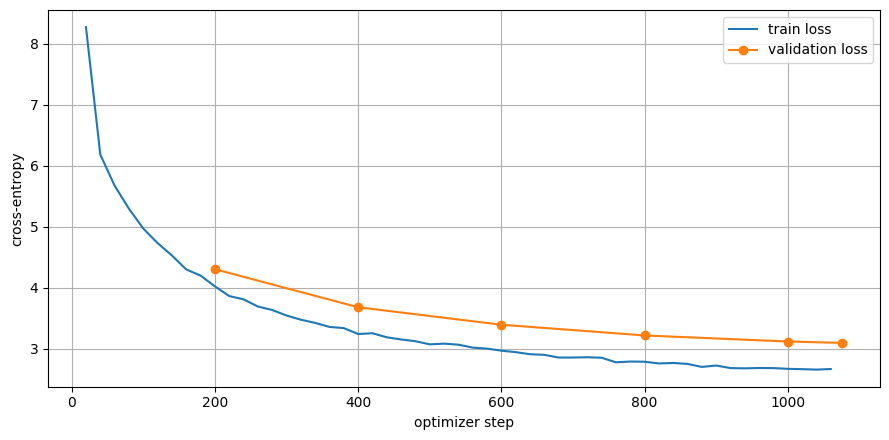

In [12]:
import matplotlib.pyplot as plt
hist = json.load(open(HISTORY_PATH))
tr = [(h["step"], h["train_loss"]) for h in hist if "train_loss" in h]
va = [(h["step"], h["val_loss"]) for h in hist if "val_loss" in h]
plt.figure(figsize=(9, 4.5))
plt.plot(*zip(*tr), label="train loss"); plt.plot(*zip(*va), marker="o", label="validation loss")
plt.xlabel("optimizer step"); plt.ylabel("cross-entropy"); plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/loss_curve.png", dpi=150); plt.show()

## 9. Generation (batched, KV-cached, left-padded)
Temperature, top-p and a repetition penalty (applied to generated tokens only, so legal terms from the
prompt can still be reused). EOS is banned so every continuation reaches 128 words.

In [13]:
best = torch.load(CKPT_BEST, map_location=device)
model.load_state_dict(best["model"]); model.eval()
print("loaded best checkpoint from step", best["step"])

@torch.no_grad()
def generate(prompt_ids, max_new=MAX_NEW_TOKENS, temperature=0.3, top_p=0.9, rep_penalty=1.1):
    B, L = len(prompt_ids), max(len(p) for p in prompt_ids)
    ids = torch.full((B, L), EOS_ID, dtype=torch.long)
    valid = torch.zeros(B, L, dtype=torch.bool)
    for i, p in enumerate(prompt_ids):
        ids[i, L - len(p):] = torch.tensor(p); valid[i, L - len(p):] = True
    ids, valid = ids.to(device), valid.to(device)
    pos = (valid.long().cumsum(1) - 1).clamp(min=0)
    causal = torch.tril(torch.ones(L, L, dtype=torch.bool, device=device))
    mask = (causal[None] & (valid[:, None, :] | torch.eye(L, dtype=torch.bool, device=device)[None]))[:, None]
    caches = [(None, None)] * len(model.blocks)
    seen = torch.zeros(B, tokenizer.vocab_size, dtype=torch.bool, device=device)
    out = []
    with torch.autocast(device, dtype=torch.float16, enabled=device == "cuda"):
        logits, _, caches = model(ids, pos_ids=pos, mask=mask, caches=caches, last_only=True)
        last_pos = pos[:, -1:]
        for step in range(max_new):
            lg = logits[:, -1].float()
            lg[:, EOS_ID] = -float("inf")
            if rep_penalty != 1.0:
                lg = torch.where(seen, torch.where(lg > 0, lg / rep_penalty, lg * rep_penalty), lg)
            if temperature <= 0:
                nxt = lg.argmax(-1)
            else:
                probs = F.softmax(lg / temperature, -1)
                sp, si = probs.sort(-1, descending=True)
                drop = (sp.cumsum(-1) - sp) > top_p
                sp = sp.masked_fill(drop, 0.0)
                nxt = si.gather(1, torch.multinomial(sp / sp.sum(-1, keepdim=True), 1)).squeeze(1)
            out.append(nxt); seen[torch.arange(B, device=device), nxt] = True
            valid = torch.cat([valid, torch.ones(B, 1, dtype=torch.bool, device=device)], 1)
            last_pos = last_pos + 1
            logits, _, caches = model(nxt[:, None], pos_ids=last_pos, mask=valid[:, None, None, :],
                                      caches=caches, last_only=True)
    return torch.stack(out, 1).tolist()

PROMPT_TOKEN_CAP = CONTEXT - MAX_NEW_TOKENS

def continue_texts(prompts, batch_size=16, **gen_kw):
    """prompts: raw strings -> list of continuations (exactly <=128 words each)."""
    enc = [tokenizer.encode(normalize_text(p, KEEP_NEWLINES))[-PROMPT_TOKEN_CAP:] for p in prompts]
    order = sorted(range(len(enc)), key=lambda i: len(enc[i]))      # similar lengths -> less padding
    results = [None] * len(enc)
    for s in range(0, len(order), batch_size):
        idx = order[s:s + batch_size]
        for i, toks in zip(idx, generate([enc[i] for i in idx], **gen_kw)):
            results[i] = " ".join(tokenizer.decode(toks).split()[:TARGET_WORDS])
    return results

lens = [len(tokenizer.encode(normalize_text(p, KEEP_NEWLINES))) for p in test_prompts_raw[:300]]
print(f"test prompt tokens: median {np.median(lens):.0f}, p99 {np.percentile(lens, 99):.0f}, "
      f"cap {PROMPT_TOKEN_CAP} -> {'OK' if np.percentile(lens, 99) <= PROMPT_TOKEN_CAP else 'RAISE CONTEXT (prompts get truncated)'}")

loaded best checkpoint from step 1076
test prompt tokens: median 608, p99 714, cap 1024 -> OK


## 10. Local validation and decoding sweep
Held-out *documents* are cut into 512-word prompts and 128-word references, mimicking the test.
ROUGE-L (own implementation) is only a quick local proxy. **Confirm the final decoding choice with the
organisers' BERTScore evaluation script** (link in the assignment) on the same generations.

In [14]:
def rouge_l_f1(hyp, ref):
    h, r = hyp.split(), ref.split()
    if not h or not r: return 0.0
    prev = [0] * (len(r) + 1)
    for i in range(1, len(h) + 1):
        cur = [0] * (len(r) + 1)
        for j in range(1, len(r) + 1):
            cur[j] = prev[j - 1] + 1 if h[i - 1] == r[j - 1] else max(prev[j], cur[j - 1])
        prev = cur
    l = prev[-1]
    return 0.0 if l == 0 else 2 * (l / len(h)) * (l / len(r)) / ((l / len(h)) + (l / len(r)))

def build_local_eval(n=96):
    items = []
    for line in open(f"{OUTPUT_DIR}/val.jsonl", encoding="utf-8"):
        w = json.loads(line)["text"].split()
        if len(w) >= PROMPT_WORDS + TARGET_WORDS + 50:
            s = random.Random(len(items)).randint(0, len(w) - PROMPT_WORDS - TARGET_WORDS)
            items.append((" ".join(w[s:s + PROMPT_WORDS]),
                          " ".join(w[s + PROMPT_WORDS:s + PROMPT_WORDS + TARGET_WORDS])))
    random.Random(SEED).shuffle(items)
    return items[:n]

local = build_local_eval()
l_prompts, l_refs = [p for p, _ in local], [r for _, r in local]
DECODING = {
    "greedy_rep1.10": dict(temperature=0.0, rep_penalty=1.10),
    "greedy_rep1.20": dict(temperature=0.0, rep_penalty=1.20),
    "t0.3_p0.9_rep1.10": dict(temperature=0.3, top_p=0.9, rep_penalty=1.10),
    "t0.7_p0.9_rep1.10": dict(temperature=0.7, top_p=0.9, rep_penalty=1.10),
}
scores = {}
for name, kw in DECODING.items():
    t0 = time.time()
    hyps = continue_texts(l_prompts, **kw)
    scores[name] = float(np.mean([rouge_l_f1(h, r) for h, r in zip(hyps, l_refs)]))
    print(f"{name:20s} ROUGE-L F1 {scores[name]:.4f} | {time.time() - t0:.0f}s")
    if name == list(DECODING)[0]:
        print("  sample:", hyps[0][:300])
FINAL_DECODING = max(scores, key=scores.get)
print("selected decoding:", FINAL_DECODING)

greedy_rep1.10       ROUGE-L F1 0.2109 | 28s
  sample: for a period of one year. The learned senior counsel also pointed out that the said circular was issued in the year 1990 and the Government had not considered the case of the appellants and the same was not challenged by the appellants before the High Court. He further submitted that the decision of
greedy_rep1.20       ROUGE-L F1 0.1940 | 27s
t0.3_p0.9_rep1.10    ROUGE-L F1 0.2092 | 28s
t0.7_p0.9_rep1.10    ROUGE-L F1 0.1995 | 28s
selected decoding: greedy_rep1.10


## 11. Official test inference -> `prediction.json` -> `submission.zip`

In [15]:
test_ids = list(test_data.keys())
t0 = time.time()
final_texts = continue_texts([test_data[i]["text"] for i in test_ids], **DECODING[FINAL_DECODING])
print(f"generated {len(final_texts)} continuations in {(time.time() - t0) / 60:.1f} min")

predictions = {str(i): {"text": t} for i, t in zip(test_ids, final_texts)}
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(PREDICTION_PATH, arcname="prediction.json")        # must sit at the archive root

wc = [len(v["text"].split()) for v in predictions.values()]
assert len(predictions) == len(test_data) and min(wc) > 0
print(f"prediction.json: {len(predictions)} items | words per item: min {min(wc)}, mean {np.mean(wc):.1f}, max {max(wc)}")
print("submission archive:", SUBMISSION_ZIP, "->", zipfile.ZipFile(SUBMISSION_ZIP).namelist())

generated 1000 continuations in 4.5 min
prediction.json: 1000 items | words per item: min 32, mean 126.6, max 128
submission archive: /kaggle/working/cs781_phase1/submission.zip -> ['prediction.json']
